In [1]:
# Colab: synchronize the public GitHub repository in this one cell.
import importlib.util
import subprocess
import sys
from pathlib import Path

_IN_COLAB_RUNTIME = (
    importlib.util.find_spec('google') is not None
    and importlib.util.find_spec('google.colab') is not None
)
_REPOSITORY_URL = 'https://github.com/WenyaWeiss/sirius2026.git'
_CLONE_ROOT = Path('/content/sirius2026')

if _IN_COLAB_RUNTIME:
    if _CLONE_ROOT.exists() and not (_CLONE_ROOT / '.git').exists():
        raise RuntimeError(
            f'{_CLONE_ROOT} exists but is not a git clone. Remove that directory '
            'and rerun this cell.'
        )
    if (_CLONE_ROOT / '.git').exists():
        subprocess.run([
            'git', '-C', str(_CLONE_ROOT),
            'pull', '--ff-only', 'origin', 'main',
        ], check=True)
        _sync_action = 'Updated'
    else:
        subprocess.run([
            'git', 'clone', '--branch', 'main', '--single-branch',
            _REPOSITORY_URL, str(_CLONE_ROOT),
        ], check=True)
        _sync_action = 'Cloned'

    # Ensure reruns import modules from the freshly synchronized checkout.
    for _module_name in ('utils', 'sirius_annotation', 'tutorial_plotting', 'teacher_solutions'):
        sys.modules.pop(_module_name, None)
    get_ipython().run_line_magic('cd', str(_CLONE_ROOT))
    print(f'{_sync_action} public repository: {_CLONE_ROOT}')


In [2]:
# Resolve the synchronized project locally or in Colab.
_REQUIRED_PROJECT_FILES = (
    'tutorial_plotting.py',
    'utils.py',
    'sirius_annotation.py',
    'teacher_solutions.py',
    'vendor/mpramnist/models/MPRALegNet.py',
    'models/epoch042-r0.79896.ckpt',
    'frameworks',
    'requirements.txt',
    'motifs/H14CORE-CLUSTERED_meme_format.meme',
)
_PROJECT_CANDIDATES = []
for _candidate in [
    Path('/content/sirius2026') if _IN_COLAB_RUNTIME else None,
    Path.cwd(),
    *Path.cwd().parents,
    Path('/content/drive/MyDrive/sirius2026'),
    Path('/content/sirius_tutorial'),
    Path('/content/drive/MyDrive/sirius_tutorial'),
]:
    if _candidate is not None and _candidate not in _PROJECT_CANDIDATES:
        _PROJECT_CANDIDATES.append(_candidate)
_PROJECT_ROOT = next(
    (
        candidate for candidate in _PROJECT_CANDIDATES
        if all((candidate / relative_path).exists()
               for relative_path in _REQUIRED_PROJECT_FILES)
    ),
    None,
)
if _PROJECT_ROOT is None:
    raise FileNotFoundError(
        'A complete sirius2026 clone was not found. In Colab, rerun the first '
        'cell to clone or pull the public GitHub repository.'
    )
sys.path.insert(0, str(_PROJECT_ROOT))
print(f'Project root: {_PROJECT_ROOT}')


Project root: /home/kekulen/ml_projects/sirius


In [3]:
!pip install -q -r "{_PROJECT_ROOT / 'requirements.txt'}"

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [4]:
# All regular imports are centralized here, immediately after dependency setup.
import json
from functools import partial

import ipywidgets as widgets
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, clear_output, display
from tangermeme.annotate import read_meme
from tangermeme.saturation_mutagenesis import saturation_mutagenesis
from tangermeme.seqlet import recursive_seqlets

from sirius_annotation import DEFAULT_MOTIF_FUNCTIONS, MotifAnnotator
from teacher_solutions import (
    BACKGROUND_SEQUENCE,
    load_natural_ism_cache,
)
from utils import (
    FitnessHead,
    decode_onehot_tensor,
    encode_core,
    fitness_from_predictions as _fitness_from_predictions,
    get_precomputed_record as _get_precomputed_record,
    insert_consensus_into_widget,
    load_example as _load_example,
    on_run,
    predict_sequences as _predict_sequences,
    render_position_aligned_macroape_logo,
    run_custom_sequence_widget,
    run_ism as _run_ism,
    select_non_overlapping_macroape_hits,
    show_example as _show_example,
)


# Интерпретация sequence2function-моделей на примере lentiMPRA


## Биологический контекст: что измеряет Agarwal lentiMPRA

В lentiMPRA тысячи 200-нуклеотидных регуляторных фрагментов встраиваются в lentiviral reporter-конструкции. Для каждого фрагмента связываются баркоды, затем секвенируются:

- **DNA barcode counts** — сколько конструкций присутствует;
- **RNA barcode counts** — сколько reporter-транскрипта произведено.

Активность элемента приблизительно определяется как:

$activity = \log_2(\text{RNA counts}/\text{DNA counts})$

В совместном Agarwal-наборе один и тот же фрагмент оценивался в трёх контекстах:

- **HepG2** — печёночно-подобная клеточная линия;
- **K562** — лейкозная клеточная линия с эритроидными особенностями;
- **WTC11** — линия индуцированных плюрипотентных клеток.

Это не измерение экспрессии гена в его естественном локусе, поскольку репортер находится в случайных местах интеграции, а исходные энхансер-промотерные контакты и локальная 3D-хроматиновая среда не сохраняются полностью.

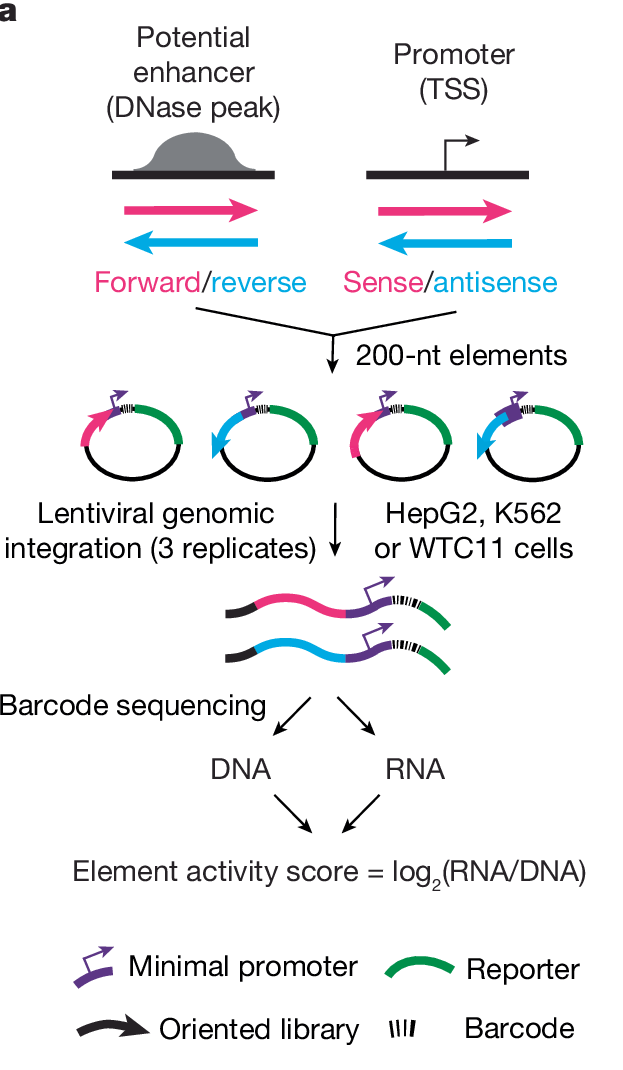

In [5]:
display(Image(filename=str(_PROJECT_ROOT / 'pics' / 'AGARWAL_mpra.png'), width=450))


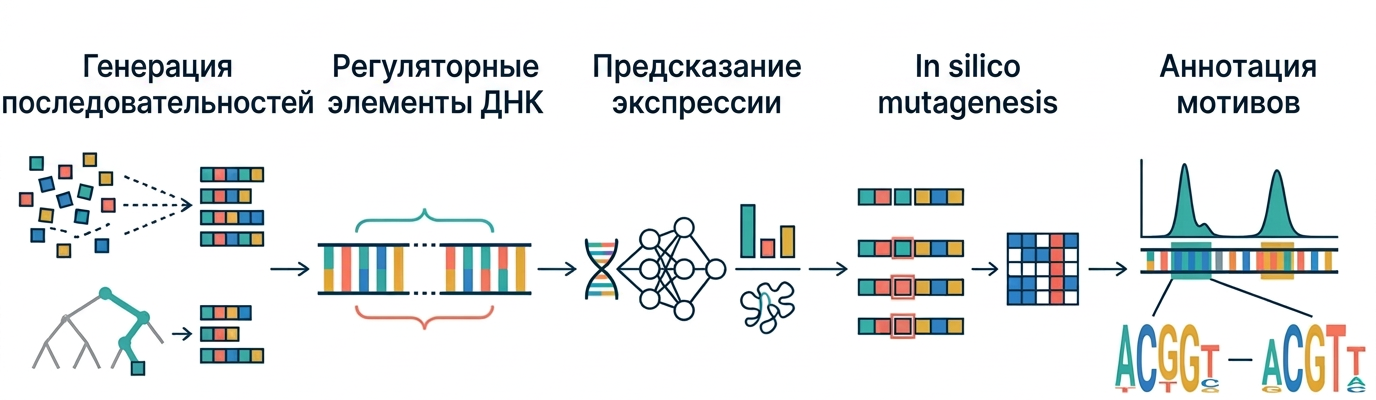

In [6]:
display(Image(filename=str(_PROJECT_ROOT / 'pics' / 'pipeline.png'), width=1100))


## Что такое sequence2function-модель

Пусть `s` — DNA-последовательность. Модель аппроксимирует функцию:


$f_\theta(s) = (y_{HepG2}, y_{K562}, y_{WTC11})$

Модель предсказатель получает one-hot представление последовательности и извлекает локальные и более длинные комбинации сигналов с помощью свёрточных блоков. В конце общие признаки поступают в голову с тремя регрессионными выходами.

Значение `predicted_*` — это прогноз модели. Значение `queried_*` в файлах генерации — **целевой профиль, который был запрошен у генератора**.

## Attribution: что именно мы хотим объяснить

**Attribution** — это способ сопоставить предсказание модели с входом: каждому основанию или позиции приписывается число, отражающее её влияние на выбранную целевую функцию.

Для модели на основе последовательности важно заранее выбрать, какой эффект мы хотим предсказывать:

- `activity HepG2` — абсолютный прогноз в HepG2;
- `activity K562` — абсолютный прогноз в K562;
- `HepG2 − K562` — клеточный контраст;
- `MinGap HepG2 = HepG2 − max(K562, WTC11)` — активность в таргетной клеточной линии относительно остальных

Одна и та же последовательность может иметь разные карты attribution для разных таргетов.

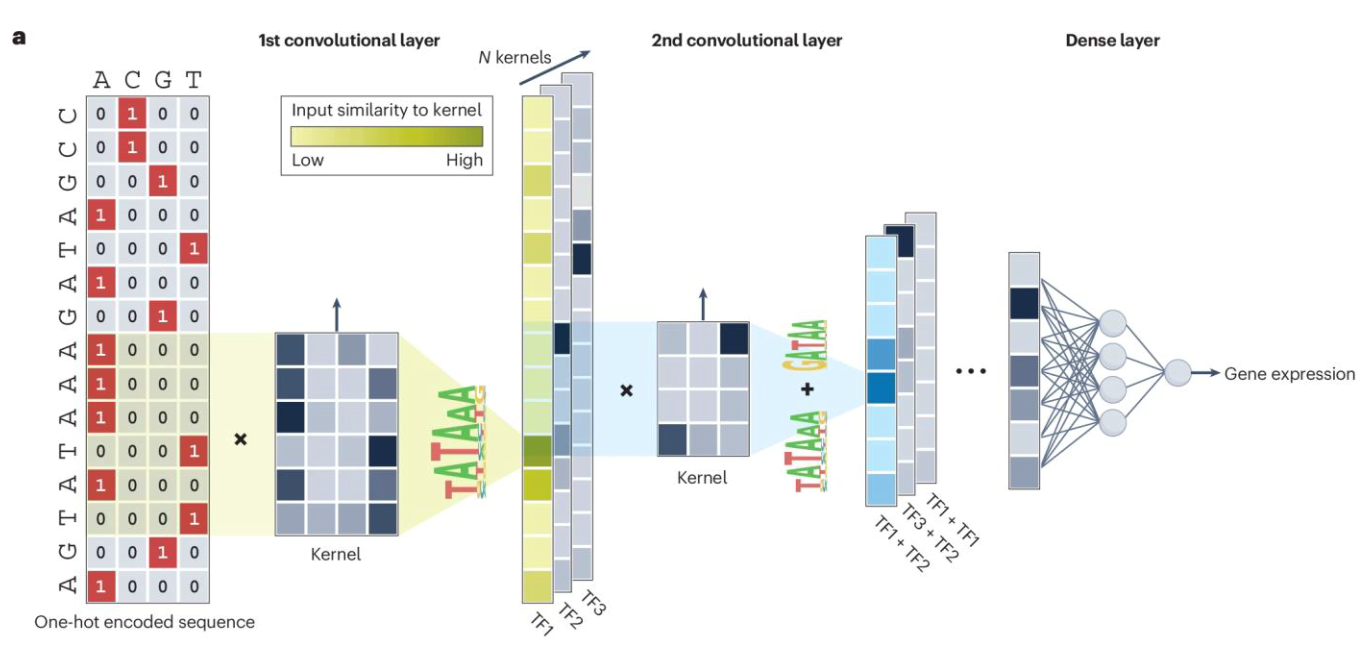

In [7]:
display(Image(filename=str(_PROJECT_ROOT / 'pics' / 'motifs_incnn.png'), width=1100))


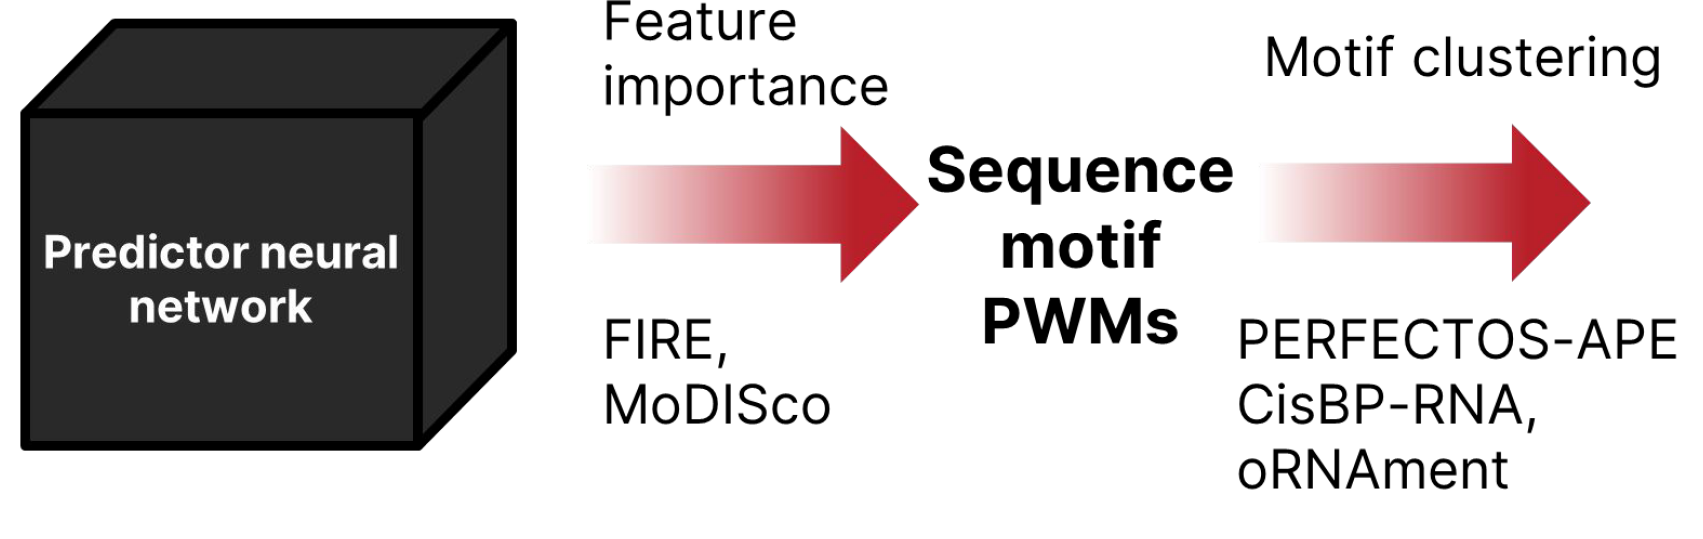

In [8]:
display(Image(filename=str(_PROJECT_ROOT / 'pics' / 'import.png'), width=1100))


## ISM: In-silico saturation mutagenesis

In-silico saturation mutagenesis (ISM) перебирает все одиночные замены:


$\Delta_{i,b} = f(s_{i\leftarrow b}) - f(s)$

где `i` — позиция, а `b` — один из A/C/G/T.

В Tangermeme для каждой позиции также центрируют эффекты относительно среднего по четырём основаниям. Получается **hypothetical attribution** размерности `4 × L`: что сказала бы модель, если в позиции стояла каждая из букв.

Умножение на исходный one-hot и суммирование по алфавиту даёт **projected attribution** — сигнал для реально присутствующего основания.

**Почему ISM полезен:** он не требует градиентов, непосредственно связан с дискретной мутацией и легко объясняется биологам. **Ограничение:** это локальный анализ одиночных замен; эпистаз и совместные мутации напрямую не измеряются.

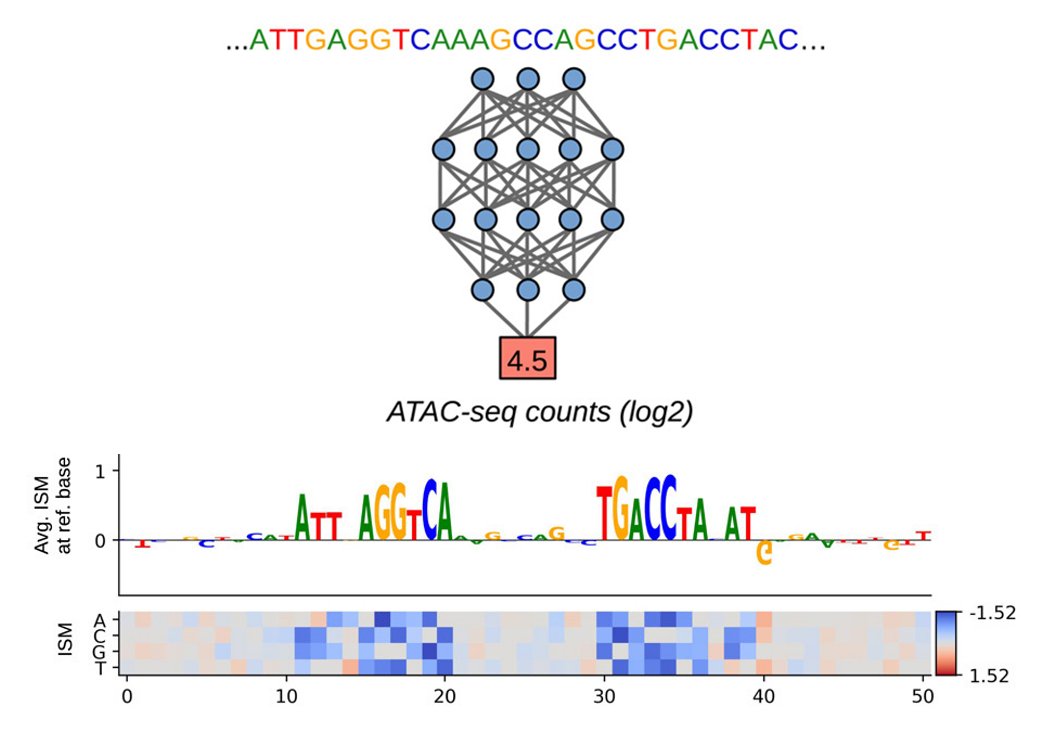

In [9]:
display(Image(filename=str(_PROJECT_ROOT / 'pics' / 'ISM_1.png'), width=950))


In [10]:



if torch.cuda.is_available():
    DEVICE = 'cuda:1' if torch.cuda.device_count() > 1 else 'cuda:0'
else:
    DEVICE = 'cpu'
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)
if DEVICE.startswith('cuda'):
    print('GPU:', torch.cuda.get_device_name(torch.device(DEVICE)))

PyTorch: 2.6.0+cu124
Device: cuda:1
GPU: NVIDIA GeForce RTX 3090


In [11]:
PORTABLE_ROOT = _PROJECT_ROOT
FRAMEWORK_DIR = PORTABLE_ROOT / 'frameworks'
WEIGHTS_PATH = PORTABLE_ROOT / 'models' / 'epoch042-r0.79896.ckpt'
MEME_PATH = PORTABLE_ROOT / 'motifs' / 'H14CORE-CLUSTERED_meme_format.meme'

print('Tutorial assets:', PORTABLE_ROOT)
print('Framework directory:', FRAMEWORK_DIR)
print('Weights:', WEIGHTS_PATH)
print('Motif database:', MEME_PATH)


Tutorial assets: /home/kekulen/ml_projects/sirius
Framework directory: /home/kekulen/ml_projects/sirius/frameworks
Weights: /home/kekulen/ml_projects/sirius/models/epoch042-r0.79896.ckpt
Motif database: /home/kekulen/ml_projects/sirius/motifs/H14CORE-CLUSTERED_meme_format.meme


In [12]:
model_source = PORTABLE_ROOT / 'vendor' / 'mpramnist' / 'models' / 'MPRALegNet.py'
if not model_source.exists():
    raise FileNotFoundError(f'Cannot find bundled model architecture: {model_source}')
spec = importlib.util.spec_from_file_location('mpramnist_legnet_source', model_source)
legnet_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(legnet_module)

checkpoint = torch.load(WEIGHTS_PATH, map_location='cpu', weights_only=False)

hparams = checkpoint['hyper_parameters']
CELL_TYPES = list(hparams['celltypes'])
model_config = dict(hparams['model_config'])
model_config.pop('left_flank', None)
model_config.pop('right_flank', None)
net = legnet_module.HumanLegNet(in_ch=4, output_dim=len(CELL_TYPES), **model_config)
net.load_state_dict({
    key[len('model.'):]: value
    for key, value in checkpoint['state_dict'].items()
    if key.startswith('model.')
})
net = net.to(DEVICE).eval()

state = checkpoint['state_dict']
ASSAY_LEFT = decode_onehot_tensor(state['left_flank']) if 'left_flank' in state else 'AGGACCGGATCAACT'
ASSAY_RIGHT = decode_onehot_tensor(state['right_flank']) if 'right_flank' in state else 'CATTGCGTGAACCGA'

print('Cell types:', CELL_TYPES)
print('Architecture:', model_config)
print('Model source:', model_source)
print('Assay flanks:', ASSAY_LEFT, ASSAY_RIGHT)
print('Checkpoint epoch:', checkpoint.get('epoch'))


Cell types: ['HepG2', 'K562', 'WTC11']
Architecture: {'stem_ch': 64, 'stem_ks': 11, 'ef_ks': 9, 'ef_block_sizes': [80, 96, 112, 128], 'pool_sizes': [2, 2, 2, 2], 'resize_factor': 4}
Model source: /home/kekulen/ml_projects/sirius/vendor/mpramnist/models/MPRALegNet.py
Assay flanks: AGGACCGGATCAACT CATTGCGTGAACCGA
Checkpoint epoch: 42


In [13]:

predict_sequences = partial(
    _predict_sequences,
    net=net,
    left_flank=ASSAY_LEFT,
    right_flank=ASSAY_RIGHT,
    device=DEVICE,
)

smoke_file = sorted(FRAMEWORK_DIR.glob('*.tsv'))[0]
smoke_seq = pd.read_csv(smoke_file, sep='\t', nrows=1).loc[0, 'sequence']
print('Smoke prediction:', dict(zip(CELL_TYPES, np.round(predict_sequences([smoke_seq])[0], 3))))


Smoke prediction: {'HepG2': np.float32(-1.436), 'K562': np.float32(-1.563), 'WTC11': np.float32(-1.116)}


## Fitness-функции для attribution

Внутри модели три выхода. Чтобы получить одну карту ISM, выбираем скалярную fitness-функцию. Это важный ML-момент: attribution относится не просто к последовательности, а к паре **(последовательность, target function)**.

In [14]:
FITNESS_NAMES = [
    'activity HepG2', 'activity K562', 'activity WTC11',
    'HepG2 - K562', 'K562 - HepG2',
    'MinGap HepG2', 'MinGap K562', 'MinGap WTC11',
]

fitness_from_predictions = partial(
    _fitness_from_predictions,
    cell_types=CELL_TYPES,
)
fitness_head_factory = partial(
    FitnessHead,
    net=net,
    cell_types=CELL_TYPES,
)


## Запускаем ISM только на центральной вставке

Tangermeme вернёт hypothetical attribution для всех четырёх оснований в каждой из 200 позиций. Один запуск для одной последовательности и одного fitness — это примерно `200 × 4` однонуклеотидных вариантов, каждый из которых проходит через предсказатель.

In [15]:

_ISM_PRECOMPUTED = {}
if _IN_COLAB_RUNTIME:
    _ism_cache_path = PORTABLE_ROOT / 'annotations' / 'precomputed_macroape.json'
    if _ism_cache_path.exists():
        _ism_cache_blob = json.loads(_ism_cache_path.read_text())
        for _entry in _ism_cache_blob.get('entries', {}).values():
            if _entry.get('ism') is not None:
                _ISM_PRECOMPUTED[(
                    str(_entry['sequence']),
                    str(_entry['fitness']),
                )] = _entry['ism']

_TEACHER_NATURAL_CACHE_ROOT = PORTABLE_ROOT / 'examples' / 'teacher_natural_cache'
if not _TEACHER_NATURAL_CACHE_ROOT.exists():
    raise FileNotFoundError(
        f'Natural teacher cache is missing: {_TEACHER_NATURAL_CACHE_ROOT}'
    )
_ISM_PRECOMPUTED.update(load_natural_ism_cache(_TEACHER_NATURAL_CACHE_ROOT))

ISM_DTYPE = torch.bfloat16 if DEVICE == 'cpu' else None
ISM_VERBOSE = DEVICE == 'cpu'
ISM_BATCH_SIZE = 128 if DEVICE == 'cpu' else 32
print('Precomputed ISM entries:', len(_ISM_PRECOMPUTED))
print('Natural genomic cache entries:', len(load_natural_ism_cache(_TEACHER_NATURAL_CACHE_ROOT)))
print('ISM batch size:', ISM_BATCH_SIZE)

ISM_CACHE = {}
run_ism = partial(
    _run_ism,
    net=net,
    device=DEVICE,
    fitness_head_cls=fitness_head_factory,
    left_flank=ASSAY_LEFT,
    right_flank=ASSAY_RIGHT,
    saturation_mutagenesis_fn=saturation_mutagenesis,
    recursive_seqlets_fn=recursive_seqlets,
    cache=ISM_CACHE,
    batch_size=ISM_BATCH_SIZE,
    precomputed_ism=_ISM_PRECOMPUTED,
    dtype=ISM_DTYPE,
    verbose=ISM_VERBOSE,
)
print('ISM function ready: cache hits are instant; cache misses run on the selected device.')


Precomputed ISM entries: 5
Natural genomic cache entries: 5
ISM batch size: 32
ISM function ready: cache hits are instant; cache misses run on the selected device.


In [16]:
# Optional reproducibility path. Leave False for the fast cached lesson.
RECOMPUTE_NATURAL_ISM = False
if RECOMPUTE_NATURAL_ISM:

    _stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    _recomputed_natural_root = PORTABLE_ROOT / 'runs' / f'teacher_natural_cache_{_stamp}'
    subprocess.run([
        sys.executable,
        str(PORTABLE_ROOT / 'scripts' / 'build_teacher_natural_cache.py'),
        '--output-dir', str(_recomputed_natural_root),
        '--device', DEVICE,
    ], check=True)
    _ISM_PRECOMPUTED.update(load_natural_ism_cache(_recomputed_natural_root))
    ISM_CACHE.clear()
    print('Recomputed natural cache:', _recomputed_natural_root)
else:
    print('Natural examples use:', _TEACHER_NATURAL_CACHE_ROOT)


Natural examples use: /home/kekulen/ml_projects/sirius/examples/teacher_natural_cache


In [17]:
# Motif database: use the clustered HOCOMOCO v14 MEME file when available (648 representatives).
motif_db = read_meme(str(MEME_PATH))
motif_source = str(MEME_PATH)

print('Motif source:', motif_source)
print('Motifs:', len(motif_db))

Motif source: /home/kekulen/ml_projects/sirius/motifs/H14CORE-CLUSTERED_meme_format.meme
Motifs: 648


## Теперь: интерпретация натуральных геномных последовательностей



In [18]:
ALIGNED_CACHE_ROOT = PORTABLE_ROOT / 'examples' / 'interpretation_workshop_cache_consensus'
ALIGNED_FIGURE_DIR = ALIGNED_CACHE_ROOT / 'figures'
ALIGNED_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
natural_examples = pd.read_csv(
    PORTABLE_ROOT / 'examples' / 'agarwaljoint_real_examples.tsv',
    sep='\t',
).sort_values('selection_order')


ISM: precomputed cache


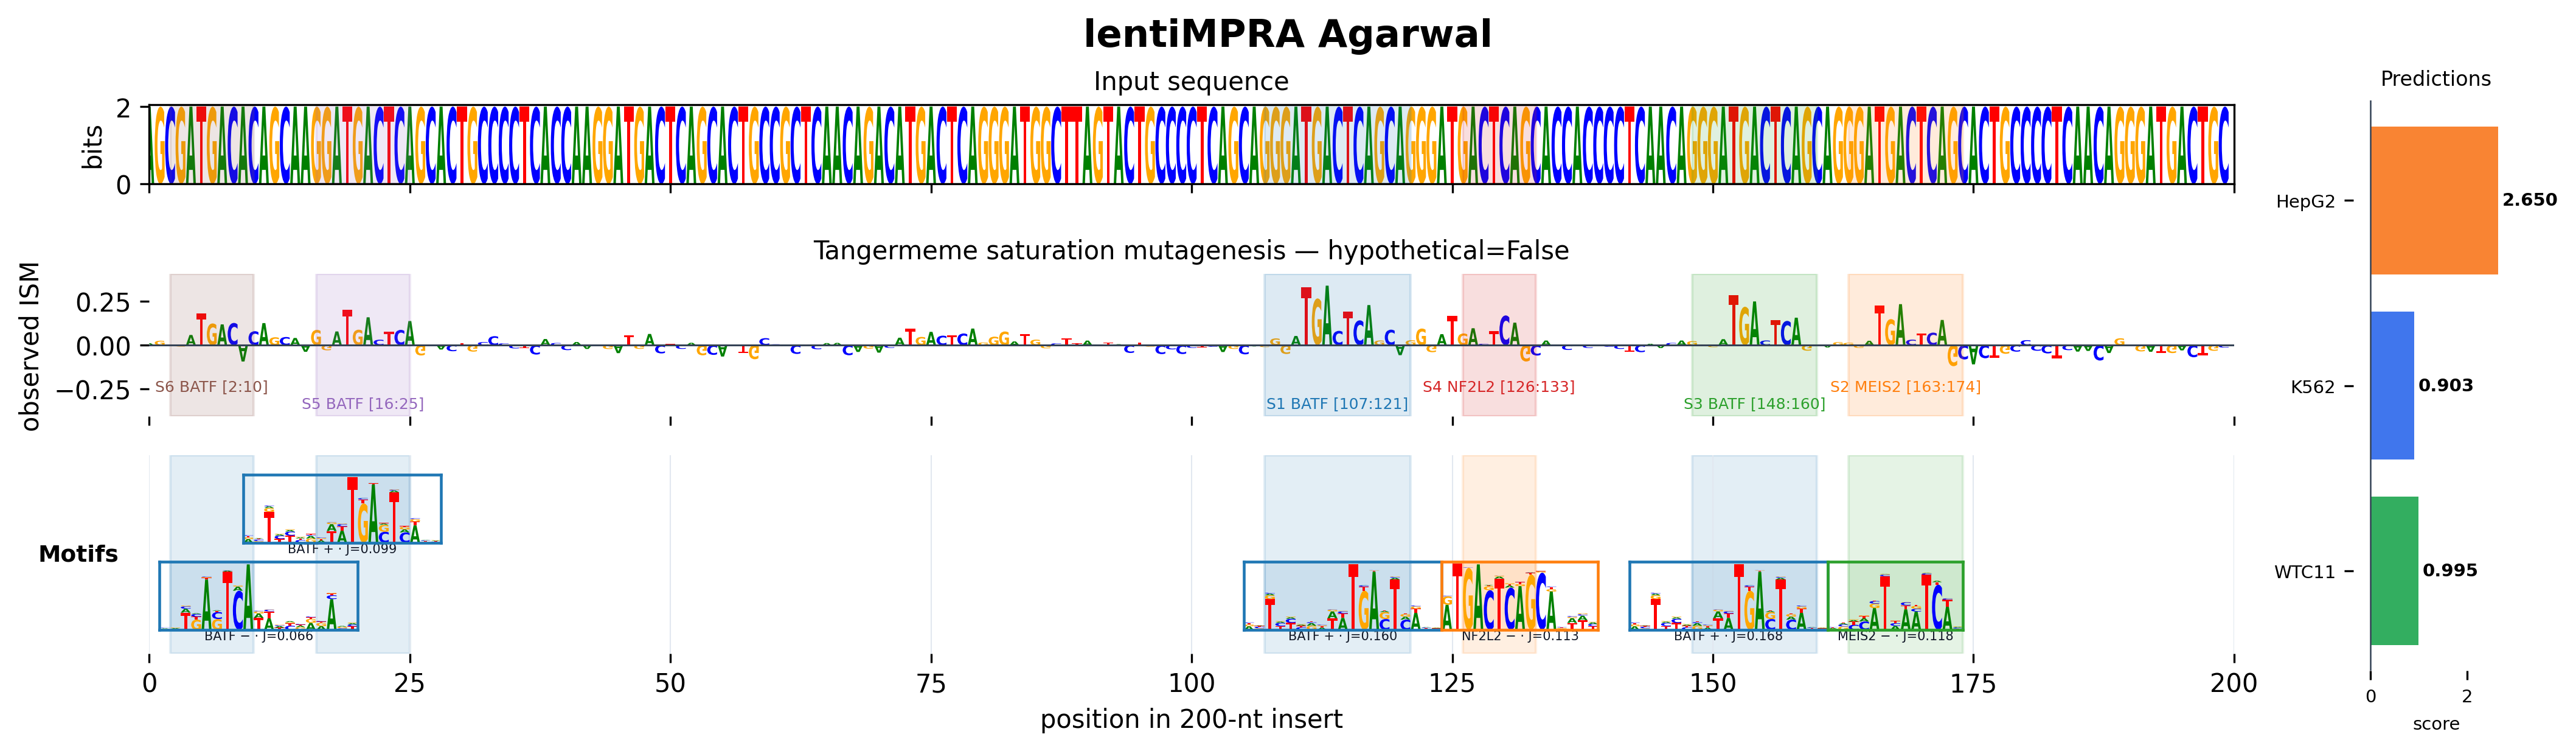

In [19]:
example = next(
    row for row in natural_examples.itertuples(index=False)
    if int(row.rank) == 74
)
natural_result = run_ism(example.sequence, 'activity HepG2')
annotation_payload = json.loads((
    ALIGNED_CACHE_ROOT / 'natural_annotations' / 'rank_0074.json'
).read_text())
annotation_payload['display_title'] = 'lentiMPRA Agarwal'
positioned_hits = select_non_overlapping_macroape_hits(
    annotation_payload,
    motif_db,
    threshold=0.05,
)
aligned_path = ALIGNED_FIGURE_DIR / 'natural_rank_0074_aligned.png'
render_position_aligned_macroape_logo(
    annotation_payload,
    natural_result['observed_attr'],
    motif_db,
    positioned_hits['motif'].drop_duplicates().tolist(),
    {
        'HepG2': float(example.prediction_HepG2),
        'K562': float(example.prediction_K562),
        'WTC11': float(example.prediction_WTC11),
    },
    aligned_path,
    threshold=0.05,
    dpi=300,
    positioned_hits=positioned_hits,
    single_motif_track=True,
    figure_width=14.0,
    figure_height=4.0,
    show_summary_panel=False,
    prediction_only_panel=True,
    frameless=True,
    horizontal_labels=True,
    show_title_counts=False,
)
display(Image(filename=str(aligned_path), width=1600))


**Теоретическая интерпретация motifs для HepG2.**

- **BATF (AP-1 family):** AP-1-подобный enhancer-сигнал; может поддерживать доступность регуляторного участка и индуцируемую транскрипцию.
- **NF2L2/NRF2:** центральный регулятор antioxidant-response elements, детоксикации и окислительного стресса — биологически правдоподобный сигнал для hepatocyte-like HepG2.
- **MEIS2:** TALE-homeobox cofactor; обычно действует совместно с другими TF и указывает на контекстную enhancer-грамматику, а не на самостоятельную HepG2-специфичность.

Это гипотезы по сходству model seqlets с HOCOMOCO motifs, а не доказательство связывания TF.


ISM: precomputed cache


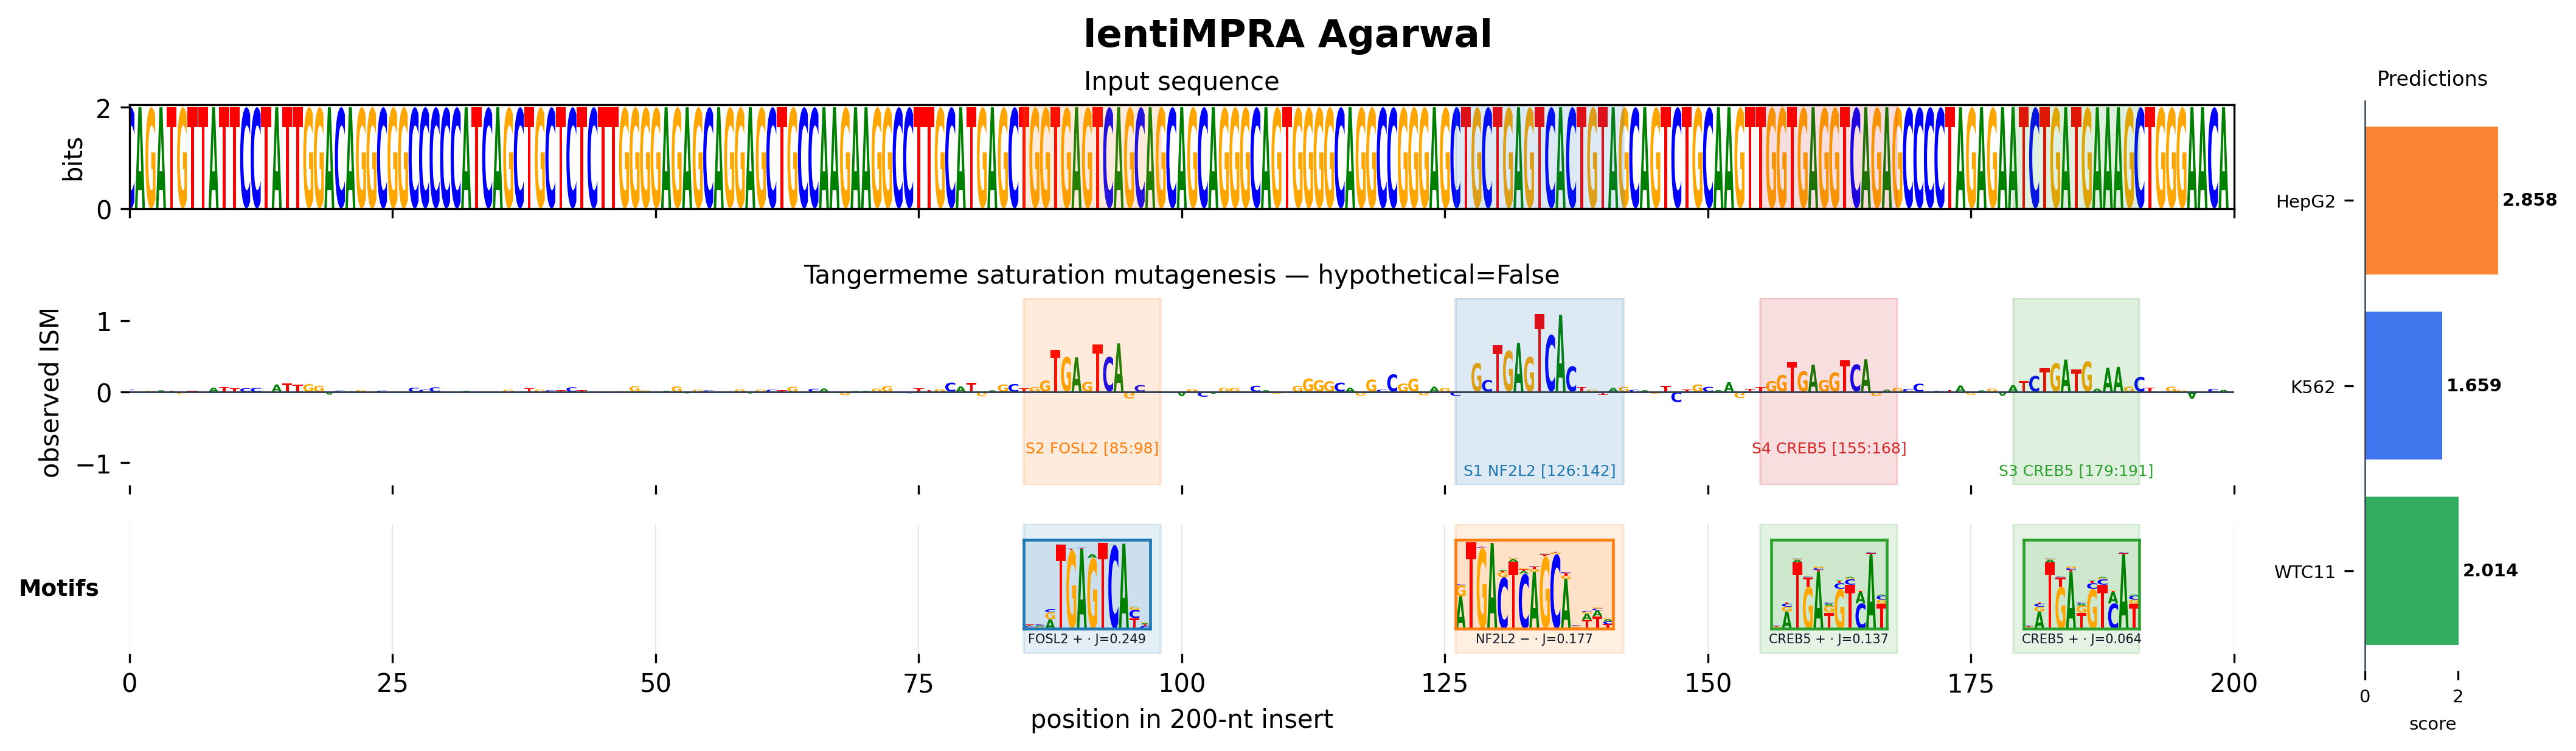

In [20]:
example = next(
    row for row in natural_examples.itertuples(index=False)
    if int(row.rank) == 51
)
natural_result = run_ism(example.sequence, 'activity HepG2')
annotation_payload = json.loads((
    ALIGNED_CACHE_ROOT / 'natural_annotations' / 'rank_0051.json'
).read_text())
annotation_payload['display_title'] = 'lentiMPRA Agarwal'
positioned_hits = select_non_overlapping_macroape_hits(
    annotation_payload,
    motif_db,
    threshold=0.05,
)
aligned_path = ALIGNED_FIGURE_DIR / 'natural_rank_0051_aligned.png'
render_position_aligned_macroape_logo(
    annotation_payload,
    natural_result['observed_attr'],
    motif_db,
    positioned_hits['motif'].drop_duplicates().tolist(),
    {
        'HepG2': float(example.prediction_HepG2),
        'K562': float(example.prediction_K562),
        'WTC11': float(example.prediction_WTC11),
    },
    aligned_path,
    threshold=0.05,
    dpi=300,
    positioned_hits=positioned_hits,
    single_motif_track=True,
    figure_width=14.0,
    figure_height=4.0,
    show_summary_panel=False,
    prediction_only_panel=True,
    frameless=True,
    horizontal_labels=True,
    show_title_counts=False,
)
display(Image(filename=str(aligned_path), width=1600))


**Теоретическая интерпретация motifs для HepG2.**

- **FOSL2/AP-1:** сильный сигнал активных и stimulus-responsive enhancers; хорошо согласуется с положительным HepG2 ISM.
- **NF2L2/NRF2:** antioxidant/detoxification program, особенно релевантный печёночному контексту.
- **CREB5:** CRE/cAMP-responsive transcription; может связывать сигнальные пути с активностью enhancer.

Совместное присутствие AP-1, NRF2 и CREB-подобных сайтов поддерживает модель комбинированной регуляции.


ISM: precomputed cache


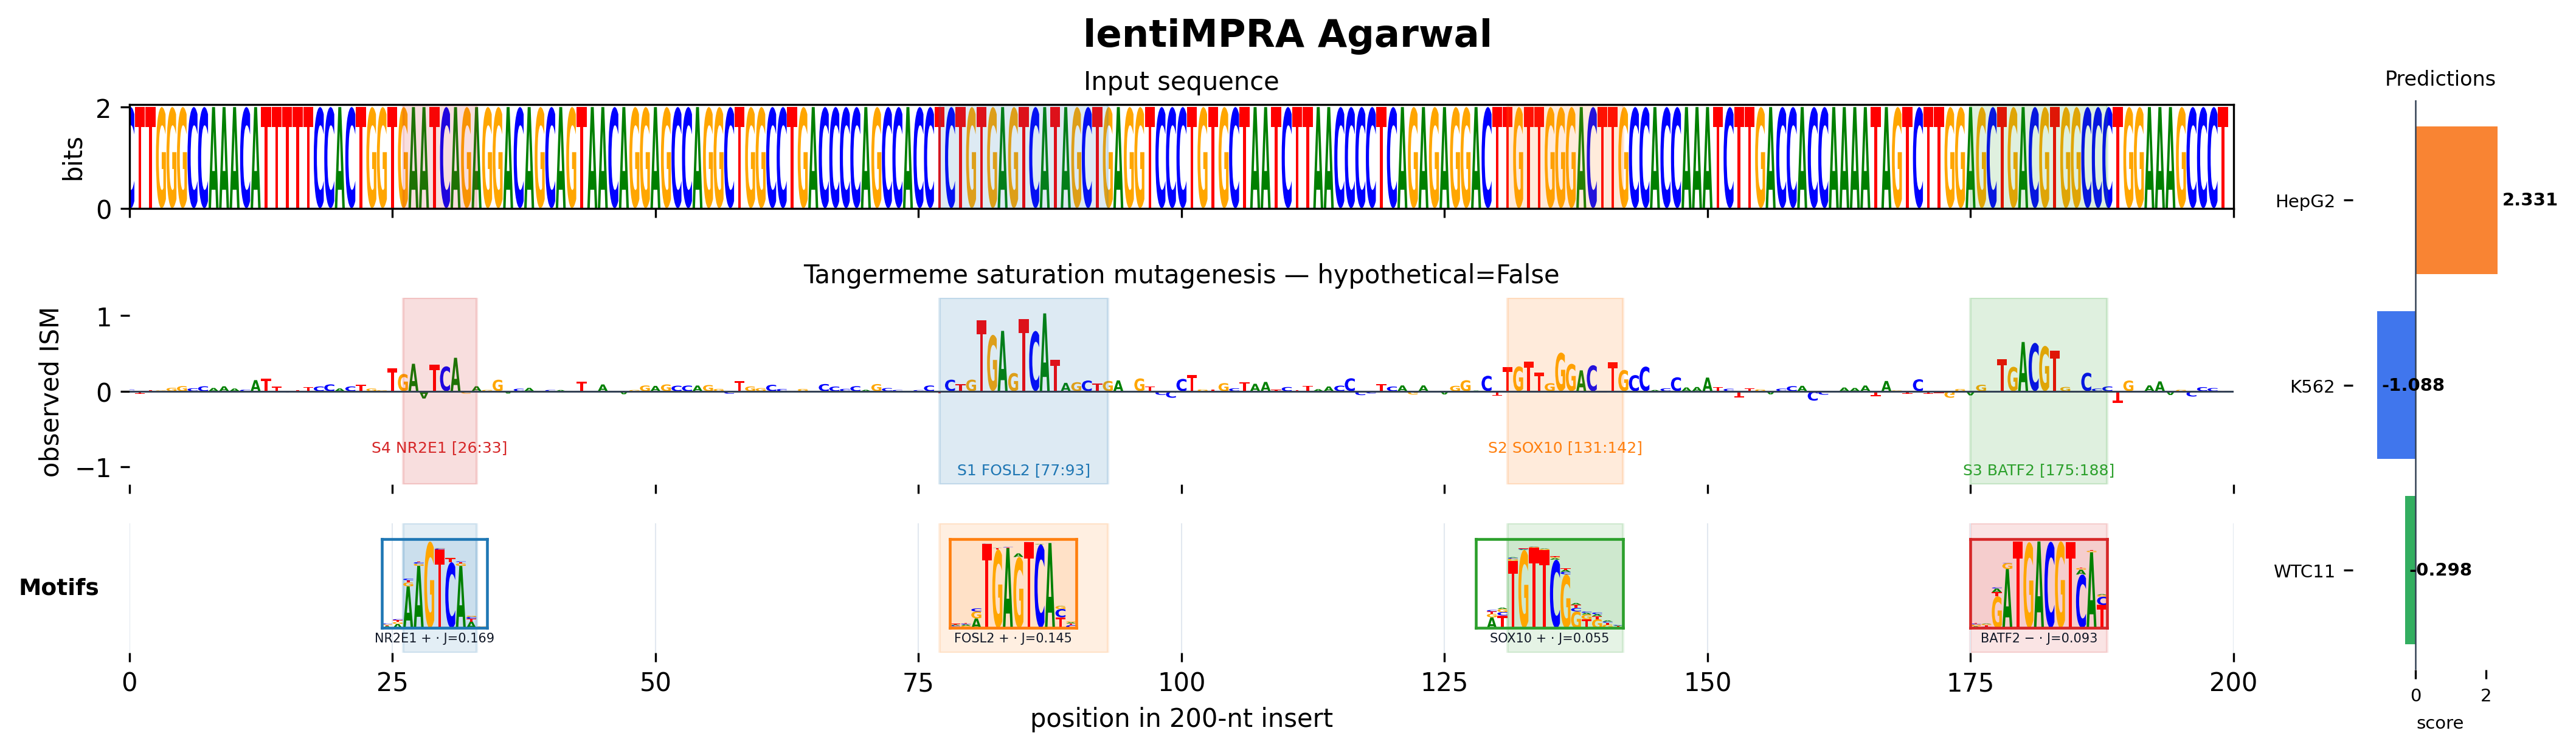

In [21]:
example = next(
    row for row in natural_examples.itertuples(index=False)
    if int(row.rank) == 119
)
natural_result = run_ism(example.sequence, 'activity HepG2')
annotation_payload = json.loads((
    ALIGNED_CACHE_ROOT / 'natural_annotations' / 'rank_0119.json'
).read_text())
annotation_payload['display_title'] = 'lentiMPRA Agarwal'
positioned_hits = select_non_overlapping_macroape_hits(
    annotation_payload,
    motif_db,
    threshold=0.05,
)
aligned_path = ALIGNED_FIGURE_DIR / 'natural_rank_0119_aligned.png'
render_position_aligned_macroape_logo(
    annotation_payload,
    natural_result['observed_attr'],
    motif_db,
    positioned_hits['motif'].drop_duplicates().tolist(),
    {
        'HepG2': float(example.prediction_HepG2),
        'K562': float(example.prediction_K562),
        'WTC11': float(example.prediction_WTC11),
    },
    aligned_path,
    threshold=0.05,
    dpi=300,
    positioned_hits=positioned_hits,
    single_motif_track=True,
    figure_width=14.0,
    figure_height=4.0,
    show_summary_panel=False,
    prediction_only_panel=True,
    frameless=True,
    horizontal_labels=True,
    show_title_counts=False,
)
display(Image(filename=str(aligned_path), width=1600))


**Теоретическая интерпретация motifs для HepG2.**

- **NR2E1:** orphan nuclear-receptor motif; в HepG2 такой match лучше трактовать как сходство с nuclear-receptor half-site, а не как доказанный NR2E1-механизм.
- **FOSL2/AP-1** и **BATF2:** AP-1-family patterns, способные маркировать активные или stress-responsive enhancers.
- **SOX10:** не является типичным HepG2 regulator; match может отражать общую SOX-подобную последовательность и подчёркивает необходимость экспериментальной проверки.


ISM: precomputed cache


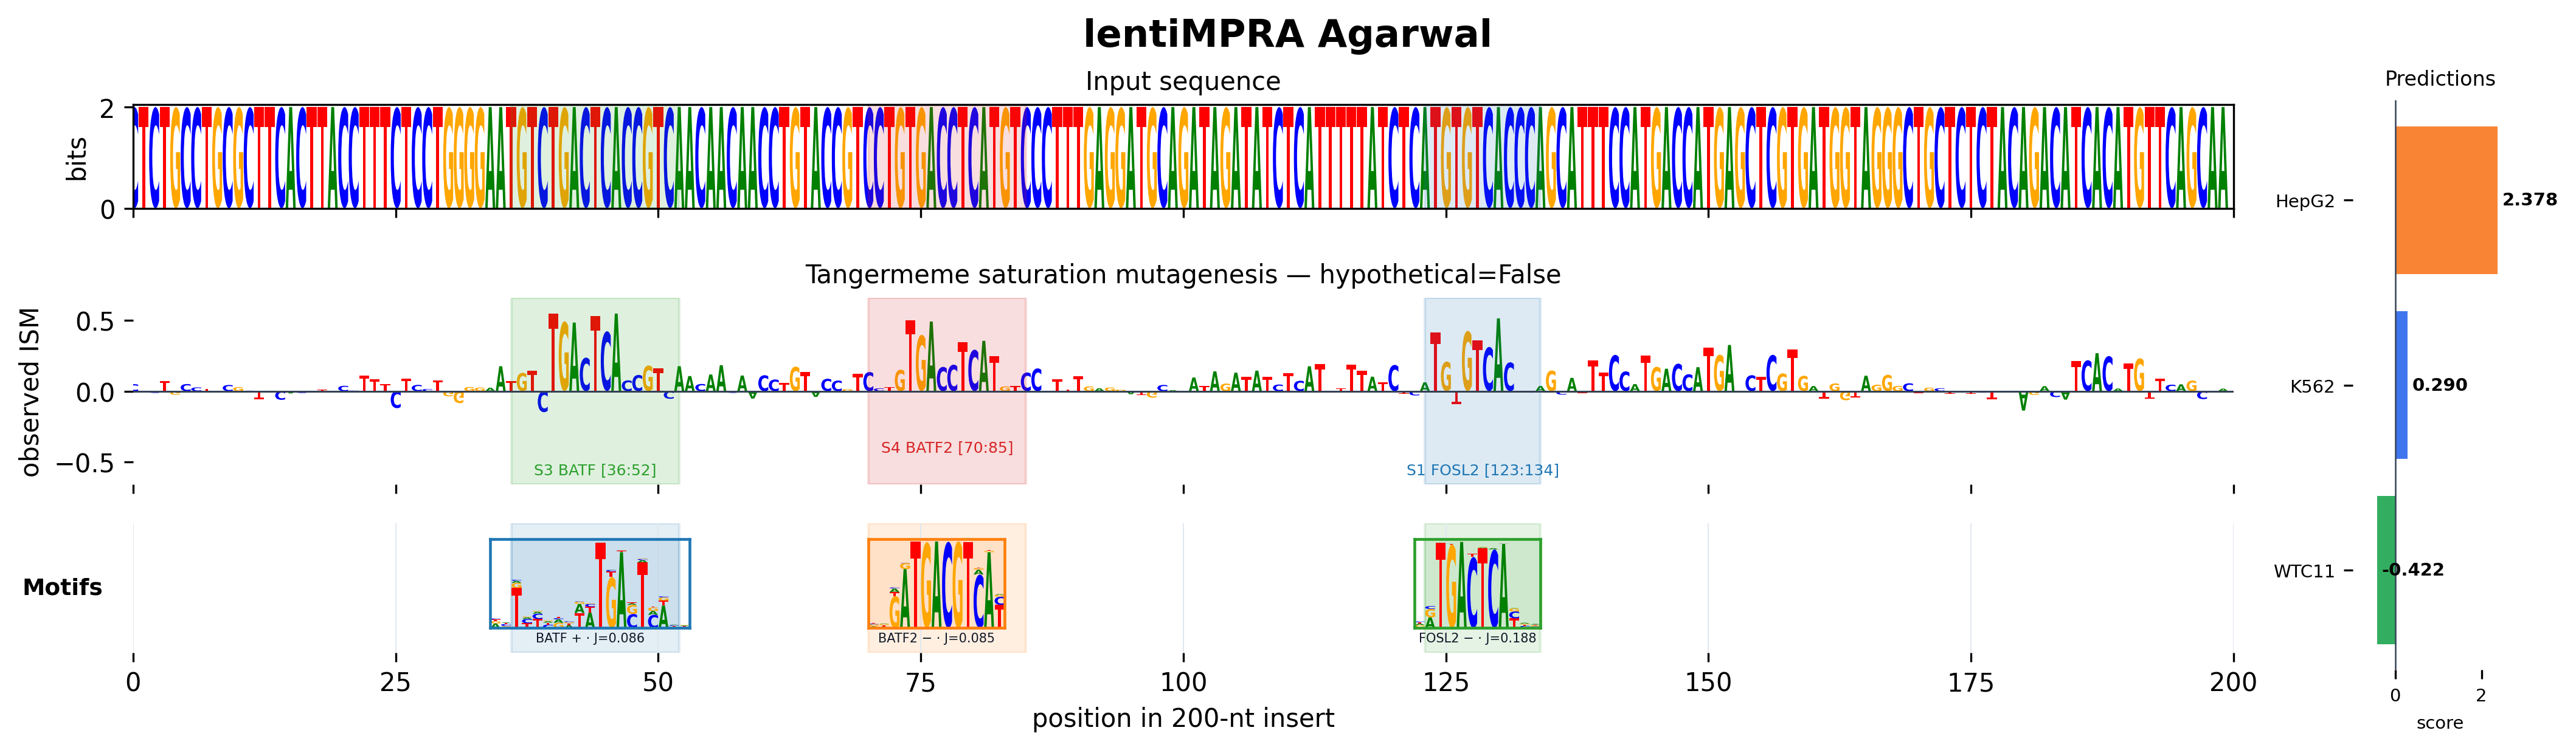

In [22]:
example = next(
    row for row in natural_examples.itertuples(index=False)
    if int(row.rank) == 114
)
natural_result = run_ism(example.sequence, 'activity HepG2')
annotation_payload = json.loads((
    ALIGNED_CACHE_ROOT / 'natural_annotations' / 'rank_0114.json'
).read_text())
annotation_payload['display_title'] = 'lentiMPRA Agarwal'
positioned_hits = select_non_overlapping_macroape_hits(
    annotation_payload,
    motif_db,
    threshold=0.05,
)
aligned_path = ALIGNED_FIGURE_DIR / 'natural_rank_0114_aligned.png'
render_position_aligned_macroape_logo(
    annotation_payload,
    natural_result['observed_attr'],
    motif_db,
    positioned_hits['motif'].drop_duplicates().tolist(),
    {
        'HepG2': float(example.prediction_HepG2),
        'K562': float(example.prediction_K562),
        'WTC11': float(example.prediction_WTC11),
    },
    aligned_path,
    threshold=0.05,
    dpi=300,
    positioned_hits=positioned_hits,
    single_motif_track=True,
    figure_width=14.0,
    figure_height=4.0,
    show_summary_panel=False,
    prediction_only_panel=True,
    frameless=True,
    horizontal_labels=True,
    show_title_counts=False,
)
display(Image(filename=str(aligned_path), width=1600))


**Теоретическая интерпретация motifs для HepG2.**

- **BATF**, **BATF2** и **FOSL2** принадлежат к AP-1-связанному motif-пространству.
- Повторные AP-1-like seqlets могут давать распределённый enhancer-сигнал и объяснять несколько положительных ISM-областей.
- Сходство между members одной motif family не позволяет однозначно выбрать конкретный TF без дополнительных данных expression/occupancy.


ISM: precomputed cache


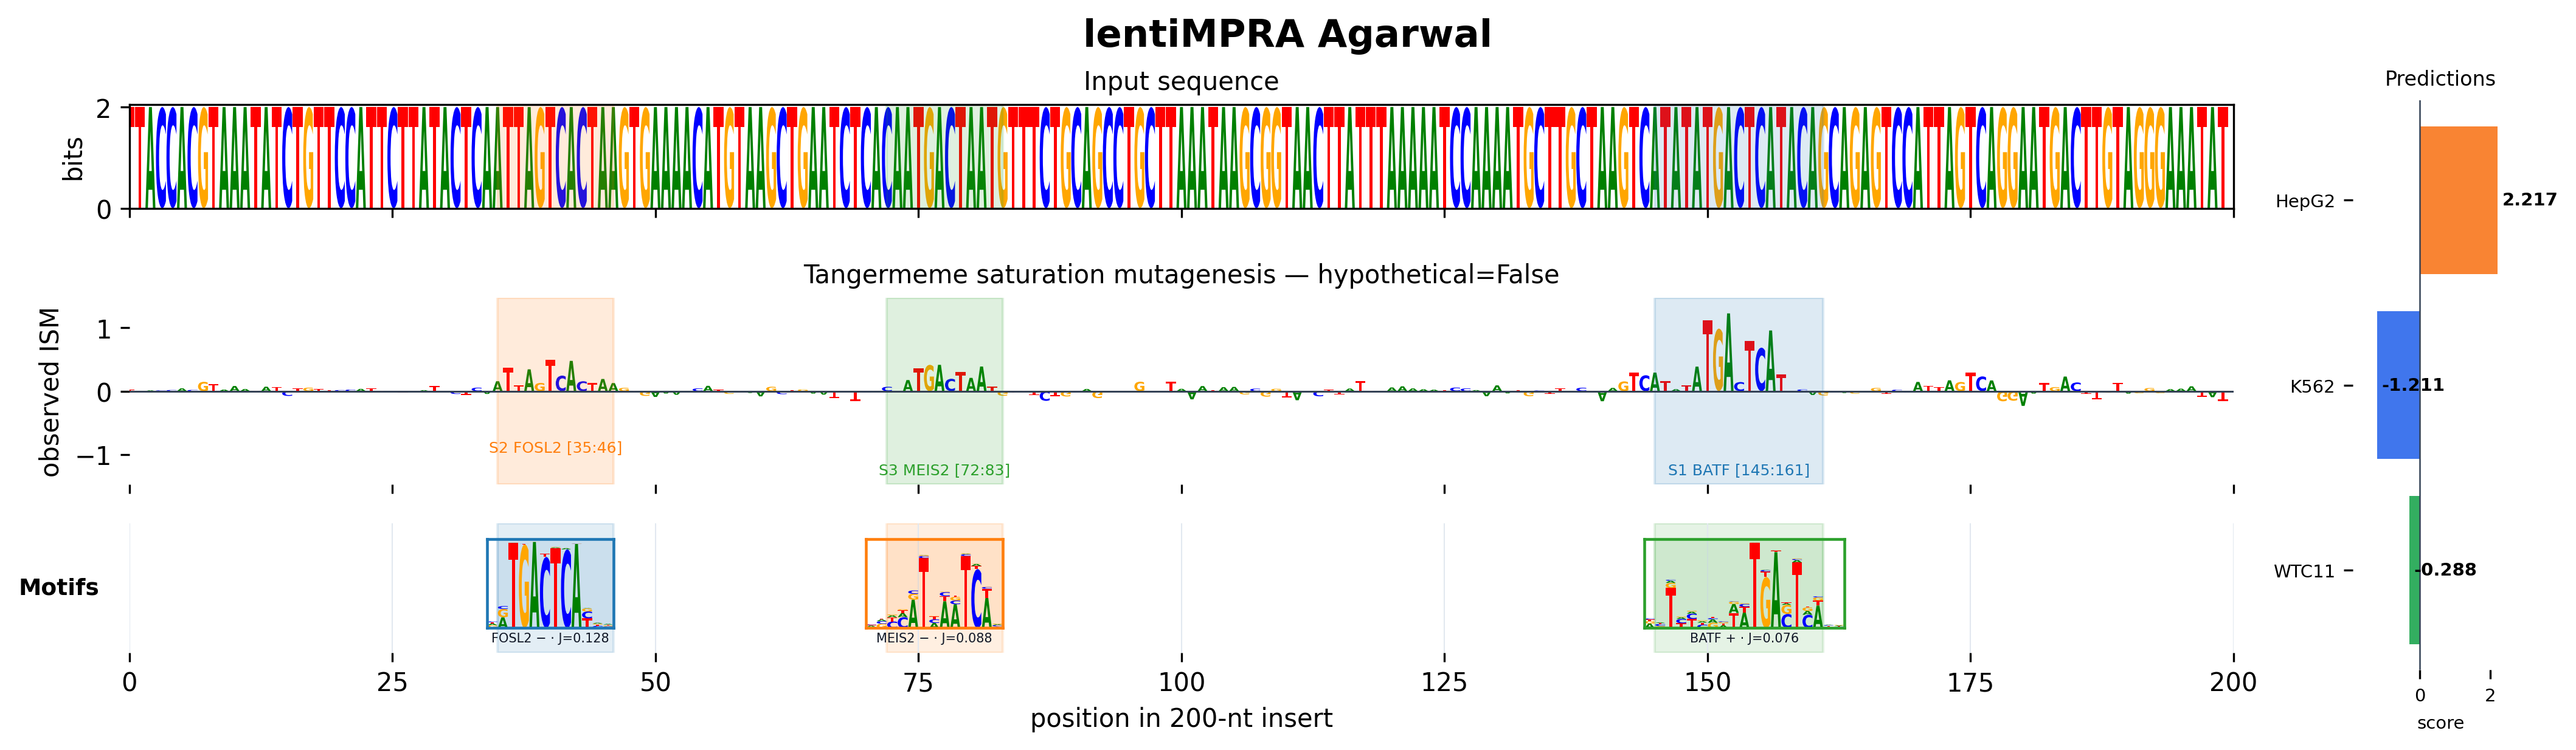

In [23]:
example = next(
    row for row in natural_examples.itertuples(index=False)
    if int(row.rank) == 150
)
natural_result = run_ism(example.sequence, 'activity HepG2')
annotation_payload = json.loads((
    ALIGNED_CACHE_ROOT / 'natural_annotations' / 'rank_0150.json'
).read_text())
annotation_payload['display_title'] = 'lentiMPRA Agarwal'
positioned_hits = select_non_overlapping_macroape_hits(
    annotation_payload,
    motif_db,
    threshold=0.05,
)
aligned_path = ALIGNED_FIGURE_DIR / 'natural_rank_0150_aligned.png'
render_position_aligned_macroape_logo(
    annotation_payload,
    natural_result['observed_attr'],
    motif_db,
    positioned_hits['motif'].drop_duplicates().tolist(),
    {
        'HepG2': float(example.prediction_HepG2),
        'K562': float(example.prediction_K562),
        'WTC11': float(example.prediction_WTC11),
    },
    aligned_path,
    threshold=0.05,
    dpi=300,
    positioned_hits=positioned_hits,
    single_motif_track=True,
    figure_width=14.0,
    figure_height=4.0,
    show_summary_panel=False,
    prediction_only_panel=True,
    frameless=True,
    horizontal_labels=True,
    show_title_counts=False,
)
display(Image(filename=str(aligned_path), width=1600))


**Теоретическая интерпретация motifs для HepG2.**

- **FOSL2/AP-1** и **BATF:** потенциальные activating/stress-responsive enhancer components.
- **MEIS2:** cofactor-like homeobox signal, который может менять эффект AP-1 в зависимости от spacing и локального контекста.
- Здесь важнее комбинация и расположение sites, чем интерпретация каждого match как независимого binding event.


## Затем: генеративные дизайны

После реальных последовательностей сравним пять заранее выбранных дизайнов MDLM и permutator. В каждом исходном TSV находятся 1024 сгенерированные последовательности.

- HepG2-specific: `mdlm_gamma0.tsv`, строка 862;
- K562-specific: `permutator_gamma0.tsv`, строка 393;
- K562-specific: `mdlm_gamma1.tsv`, строка 459;
- WTC11-specific: `mdlm_gamma0.tsv`, строка 367;
- дополнительный K562-specific: `mdlm_gamma0.tsv`, строка 649.

Это не утверждение, что такие последовательности уже экспериментально валидированы. Они нужны, чтобы показать, как модель формирует и объясняет гипотезы.

In [24]:
framework_files = sorted(FRAMEWORK_DIR.glob('*.tsv')) if FRAMEWORK_DIR.exists() else []
all_rows = []
for path in framework_files:
    d = pd.read_csv(path, sep='\t')
    pred_cols = [f'predicted_{ct}' for ct in CELL_TYPES]
    query_cols = [f'queried_{ct}' for ct in CELL_TYPES]
    pred = d[pred_cols].to_numpy()
    order = np.argsort(pred, axis=1)[:, ::-1]
    sorted_pred = np.take_along_axis(pred, order, axis=1)
    d['framework'] = path.stem
    d['row'] = np.arange(len(d))
    d['dominant_cell'] = [CELL_TYPES[i] for i in order[:, 0]]
    d['min_gap'] = sorted_pred[:, 0] - sorted_pred[:, 1]
    d['gc_fraction'] = d['sequence'].map(lambda s: (s.count('G') + s.count('C')) / len(s))
    d['prediction_error'] = np.abs(d[pred_cols].to_numpy() - d[query_cols].to_numpy()).mean(axis=1)
    all_rows.append(d)
summary_df = pd.concat(all_rows, ignore_index=True) if all_rows else pd.DataFrame()
print('Loaded files:', [p.name for p in framework_files])
print('Total sequences:', len(summary_df))
if len(summary_df):
    display(summary_df.groupby(['framework', 'dominant_cell']).size().unstack(fill_value=0))

Loaded files: ['mdlm_gamma0.tsv', 'mdlm_gamma1.tsv', 'permutator_gamma0.tsv']
Total sequences: 3072


dominant_cell,HepG2,K562,WTC11
framework,,,
mdlm_gamma0,346,222,456
mdlm_gamma1,437,336,251
permutator_gamma0,379,160,485


In [25]:
EXAMPLES = {
    'HepG2-specific / MDLM gamma0': ('mdlm_gamma0.tsv', 862, 'HepG2'),
    'K562-specific / MDLM gamma1': ('mdlm_gamma1.tsv', 459, 'K562'),
    'WTC11-specific / MDLM gamma0': ('mdlm_gamma0.tsv', 367, 'WTC11'),
}

load_example = partial(
    _load_example,
    examples=EXAMPLES,
    framework_dir=FRAMEWORK_DIR,
)

example_records = [load_example(label) for label in EXAMPLES]
example_table = pd.DataFrame(example_records)
cols = ['example', 'source_file', 'source_row', 'target']
for ct in CELL_TYPES:
    cols += [f'queried_{ct}', f'predicted_{ct}']
display(example_table[cols].round(3))


,example,source_file,source_row,target,queried_HepG2,predicted_HepG2,queried_K562,predicted_K562,queried_WTC11,predicted_WTC11
0,HepG2-specific / MDLM gamma0,mdlm_gamma0.tsv,862,HepG2,0.768,4.012,-0.138,-0.886,-0.421,0.109
1,K562-specific / MDLM gamma1,mdlm_gamma1.tsv,459,K562,-1.169,-1.164,3.957,3.783,-1.851,-1.036
2,WTC11-specific / MDLM gamma0,mdlm_gamma0.tsv,367,WTC11,-0.424,-1.073,-1.003,-1.875,0.769,3.173


In [26]:

MOTIF_FUNCTIONS = DEFAULT_MOTIF_FUNCTIONS
ANNOTATOR = MotifAnnotator(
    motif_db,
    repo_root=PORTABLE_ROOT,
    in_colab=_IN_COLAB_RUNTIME,
    encode_core=encode_core,
)
IN_COLAB = ANNOTATOR.in_colab
MACROAPE_MODE = ANNOTATOR.macroape_mode
PRECOMPUTED_CACHE = ANNOTATOR.precomputed_cache

precomputed_record = partial(
    _get_precomputed_record,
    in_colab=IN_COLAB,
    precomputed_cache=PRECOMPUTED_CACHE,
)
show_example = partial(
    _show_example,
    load_example_fn=load_example,
    run_ism_fn=run_ism,
    precomputed_record_fn=precomputed_record,
    cell_types=CELL_TYPES,
    predict_sequences_fn=predict_sequences,
    fitness_from_predictions_fn=fitness_from_predictions,
    annotator=ANNOTATOR,
    motif_db=motif_db,
    motif_functions=MOTIF_FUNCTIONS,
)


MacroAPE: enabled
Precomputed cache: /home/kekulen/ml_projects/sirius/annotations/precomputed_macroape.json | entries: 5


## Аннотация

Сначала выберите абсолютную активность. Затем переключите fitness на клеточный контраст. Карта изменится, потому что теперь модель объясняет уже не «почему активность высокая», а «почему активность выше в одной линии, чем в другой».

In [27]:

example_widget = widgets.Dropdown(options=list(EXAMPLES), value=list(EXAMPLES)[0], description='последовательность:')
fitness_widget = widgets.Dropdown(options=FITNESS_NAMES, value='activity HepG2', description='fitness:')
run_button = widgets.Button(description='Run ISM', button_style='primary')
out = widgets.Output()

run_button.on_click(partial(
    on_run,
    output_widget=out,
    clear_output_fn=clear_output,
    show_example_fn=show_example,
    example_widget=example_widget,
    fitness_widget=fitness_widget,
))
display(widgets.HBox([example_widget, fitness_widget, run_button]), out)

Output()

### Position-aligned ISM и motif track для трёх generated examples

Оба K562-примера с NANOG удалены. Для оставшихся HepG2-, K562- и WTC11-specific designs используется тот же трёхтрековый renderer; после каждой картинки следует cell-line-specific теоретическая сводка motifs.


In [28]:
generated_cache = json.loads(
    (PORTABLE_ROOT / 'annotations' / 'precomputed_macroape.json').read_text()
)
generated_entries = {
    entry['example']: entry
    for entry in generated_cache['entries'].values()
}


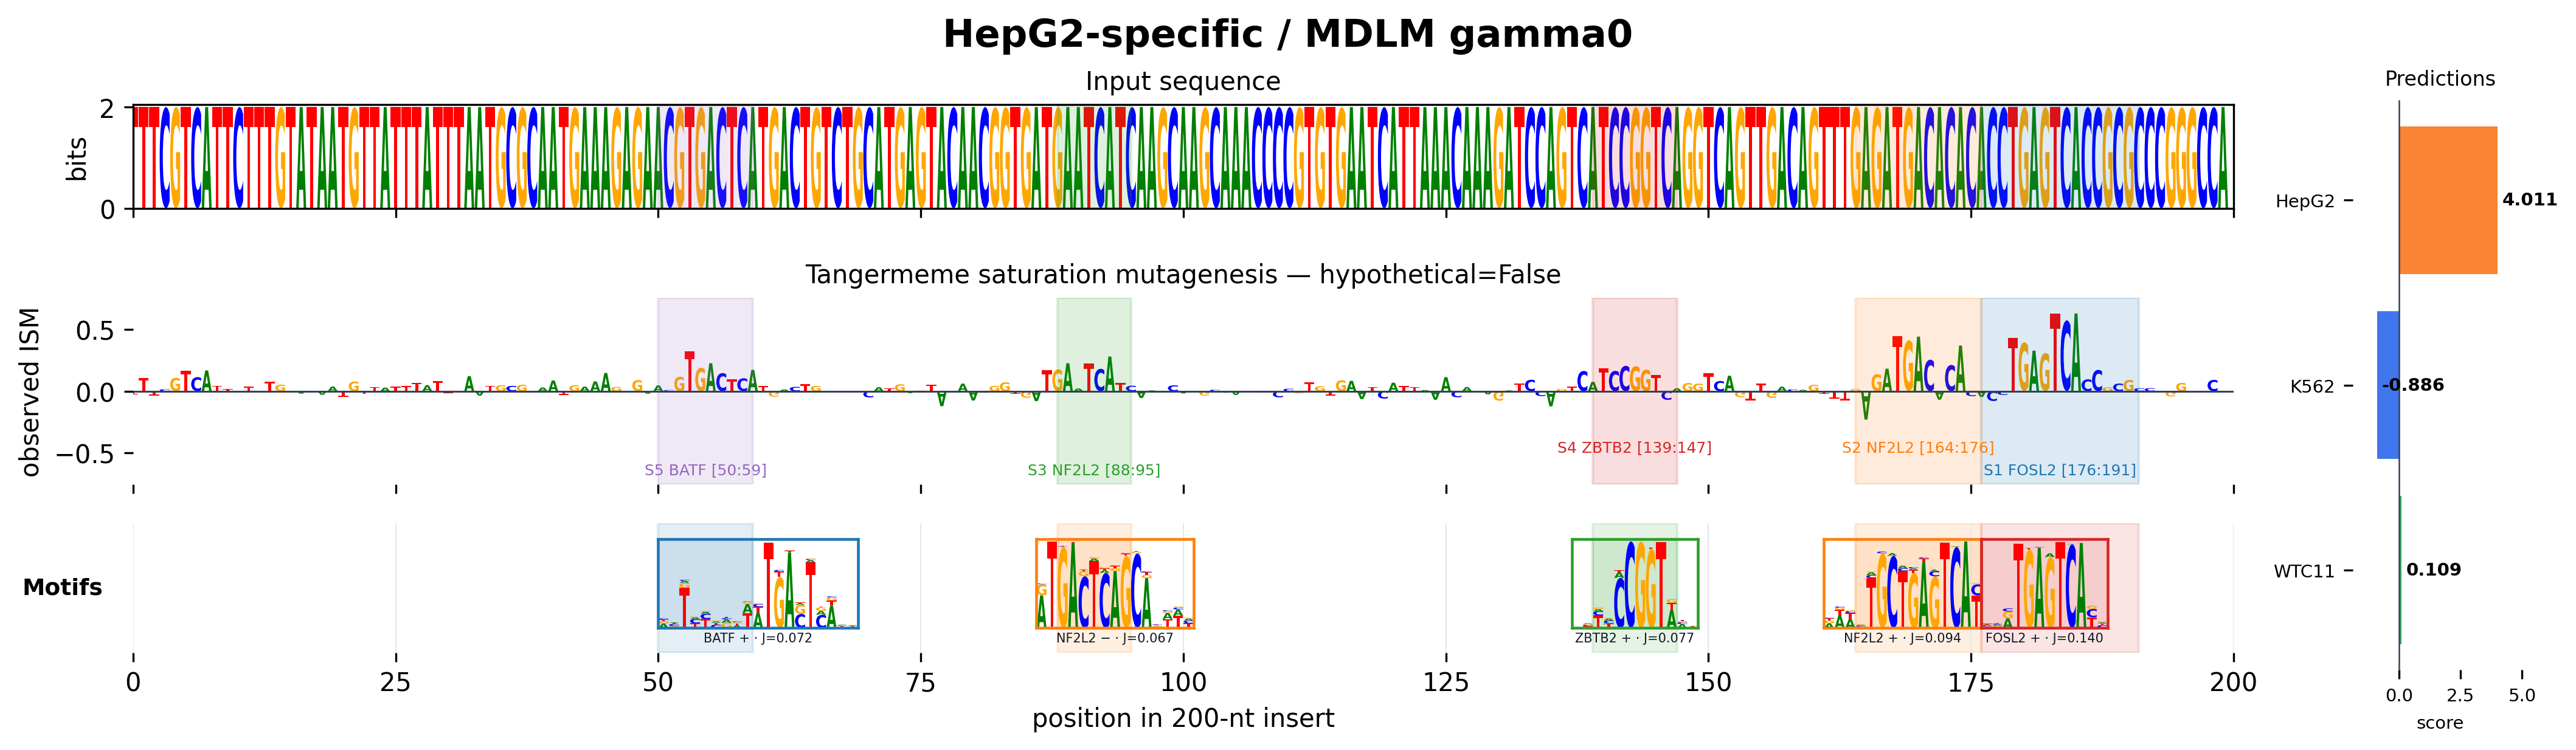

In [29]:
entry = generated_entries['HepG2-specific / MDLM gamma0']
annotation_payload = {
    'example': entry['example'],
    'source_file': entry['source_file'],
    'source_row': entry['source_row'],
    'sequence': entry['sequence'],
    'seqlets': entry['seqlets'],
    'annotation_attrs': {
        'reference_similarity_matrix': entry['reference_similarity_matrix'],
    },
    'display_title': entry['example'],
}
positioned_hits = select_non_overlapping_macroape_hits(
    annotation_payload,
    motif_db,
    threshold=0.05,
)
aligned_path = ALIGNED_FIGURE_DIR / 'generated_01_aligned.png'
render_position_aligned_macroape_logo(
    annotation_payload,
    np.asarray(entry['ism']['observed_attr']),
    motif_db,
    positioned_hits['motif'].drop_duplicates().tolist(),
    entry['predictions'],
    aligned_path,
    threshold=0.05,
    dpi=300,
    positioned_hits=positioned_hits,
    single_motif_track=True,
    figure_width=14.0,
    figure_height=4.0,
    show_summary_panel=False,
    prediction_only_panel=True,
    frameless=True,
    horizontal_labels=True,
    show_title_counts=False,
)
display(Image(filename=str(aligned_path), width=1600))


**Теоретическая интерпретация для HepG2-specific design.**

- **BATF/FOSL2 (AP-1 family):** activating enhancer-like patterns и stimulus-responsive transcription.
- **NF2L2/NRF2:** liver-relevant antioxidant/detoxification program; особенно согласуется с HepG2 specificity.
- **ZBTB2:** zinc-finger/BTB regulator, способный участвовать в transcriptional repression и chromatin regulation; его model match может модулировать AP-1/NRF2-контекст.


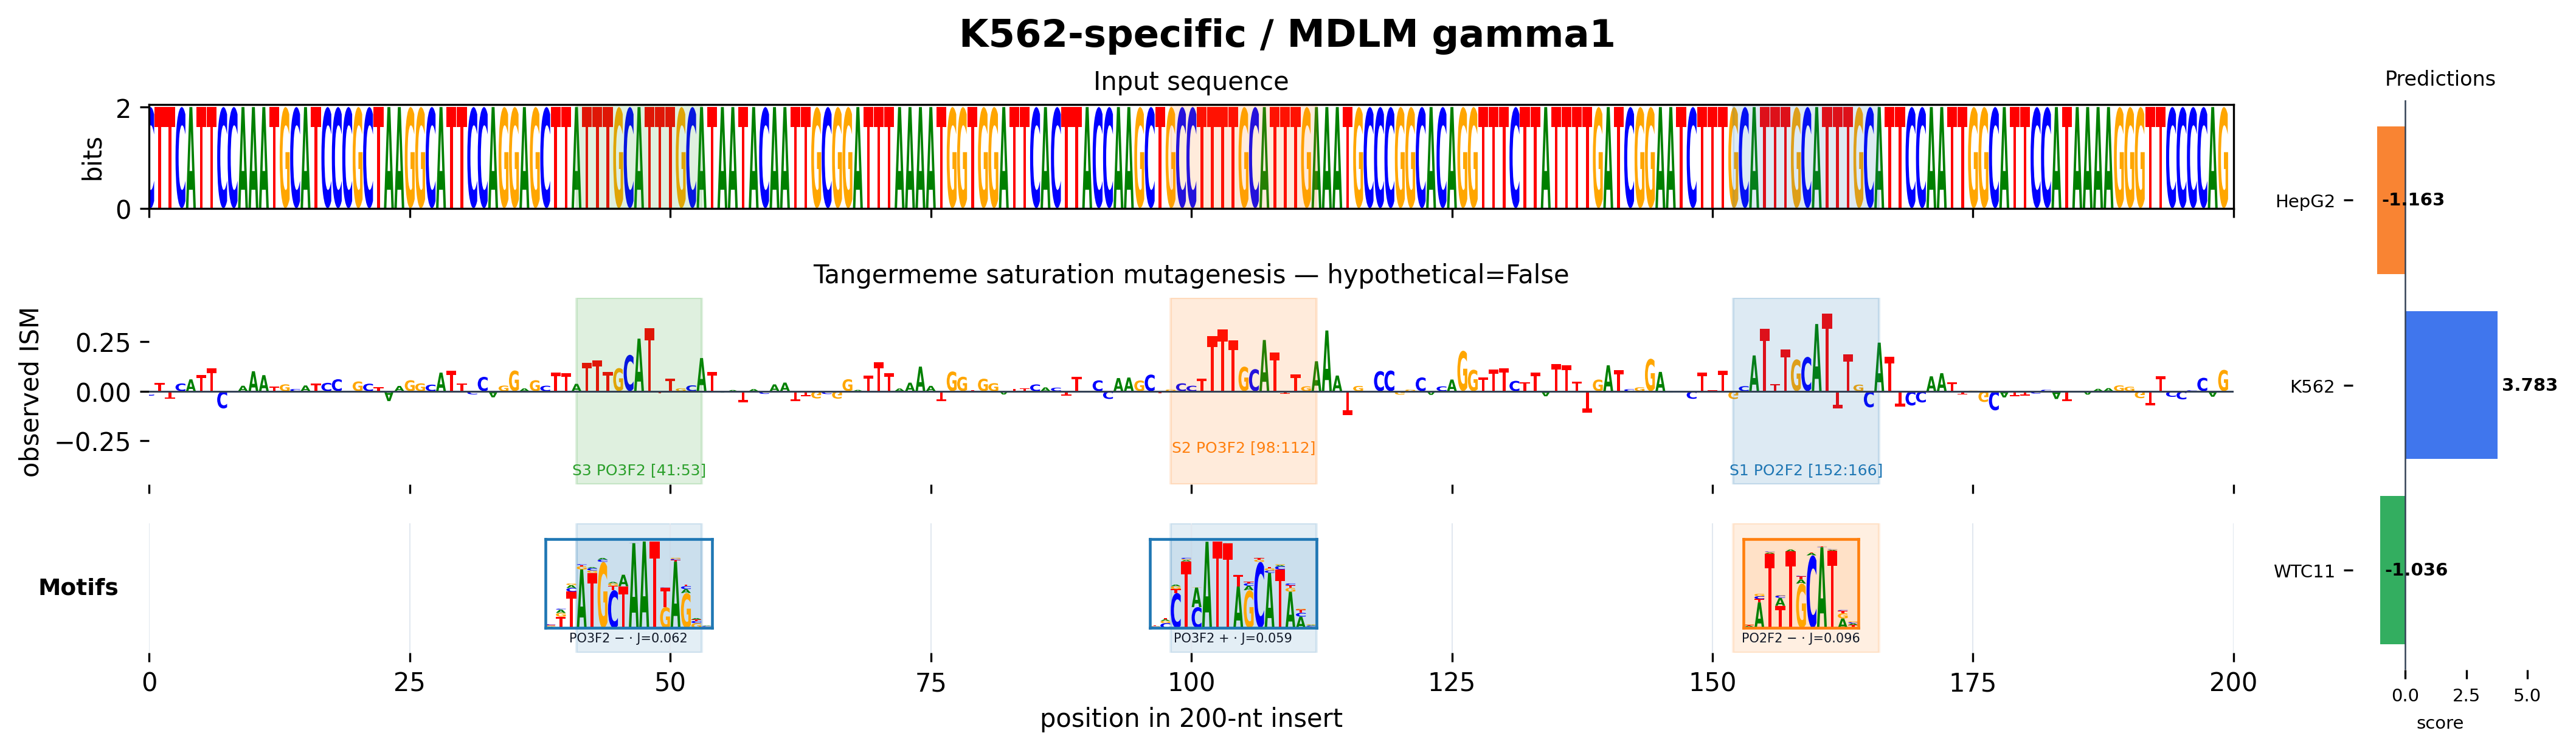

In [30]:
entry = generated_entries['K562-specific / MDLM gamma1']
annotation_payload = {
    'example': entry['example'],
    'source_file': entry['source_file'],
    'source_row': entry['source_row'],
    'sequence': entry['sequence'],
    'seqlets': entry['seqlets'],
    'annotation_attrs': {
        'reference_similarity_matrix': entry['reference_similarity_matrix'],
    },
    'display_title': entry['example'],
}
positioned_hits = select_non_overlapping_macroape_hits(
    annotation_payload,
    motif_db,
    threshold=0.05,
)
aligned_path = ALIGNED_FIGURE_DIR / 'generated_02_aligned.png'
render_position_aligned_macroape_logo(
    annotation_payload,
    np.asarray(entry['ism']['observed_attr']),
    motif_db,
    positioned_hits['motif'].drop_duplicates().tolist(),
    entry['predictions'],
    aligned_path,
    threshold=0.05,
    dpi=300,
    positioned_hits=positioned_hits,
    single_motif_track=True,
    figure_width=14.0,
    figure_height=4.0,
    show_summary_panel=False,
    prediction_only_panel=True,
    frameless=True,
    horizontal_labels=True,
    show_title_counts=False,
)
display(Image(filename=str(aligned_path), width=1600))


**Теоретическая интерпретация для K562-specific design.**

- **POU2F2/OCT2:** POU-family regulator с выраженной ролью в hematopoietic transcriptional programs; наиболее биологически правдоподобный K562-related match этого набора.
- **POU3F2:** обычно ассоциирован с neural lineage; в K562 его следует трактовать как POU-family sequence similarity, а не доказанный driver.
- Несколько POU-like sites могут отражать motif grammar, которую модель использует для отличия K562 от других выходов.


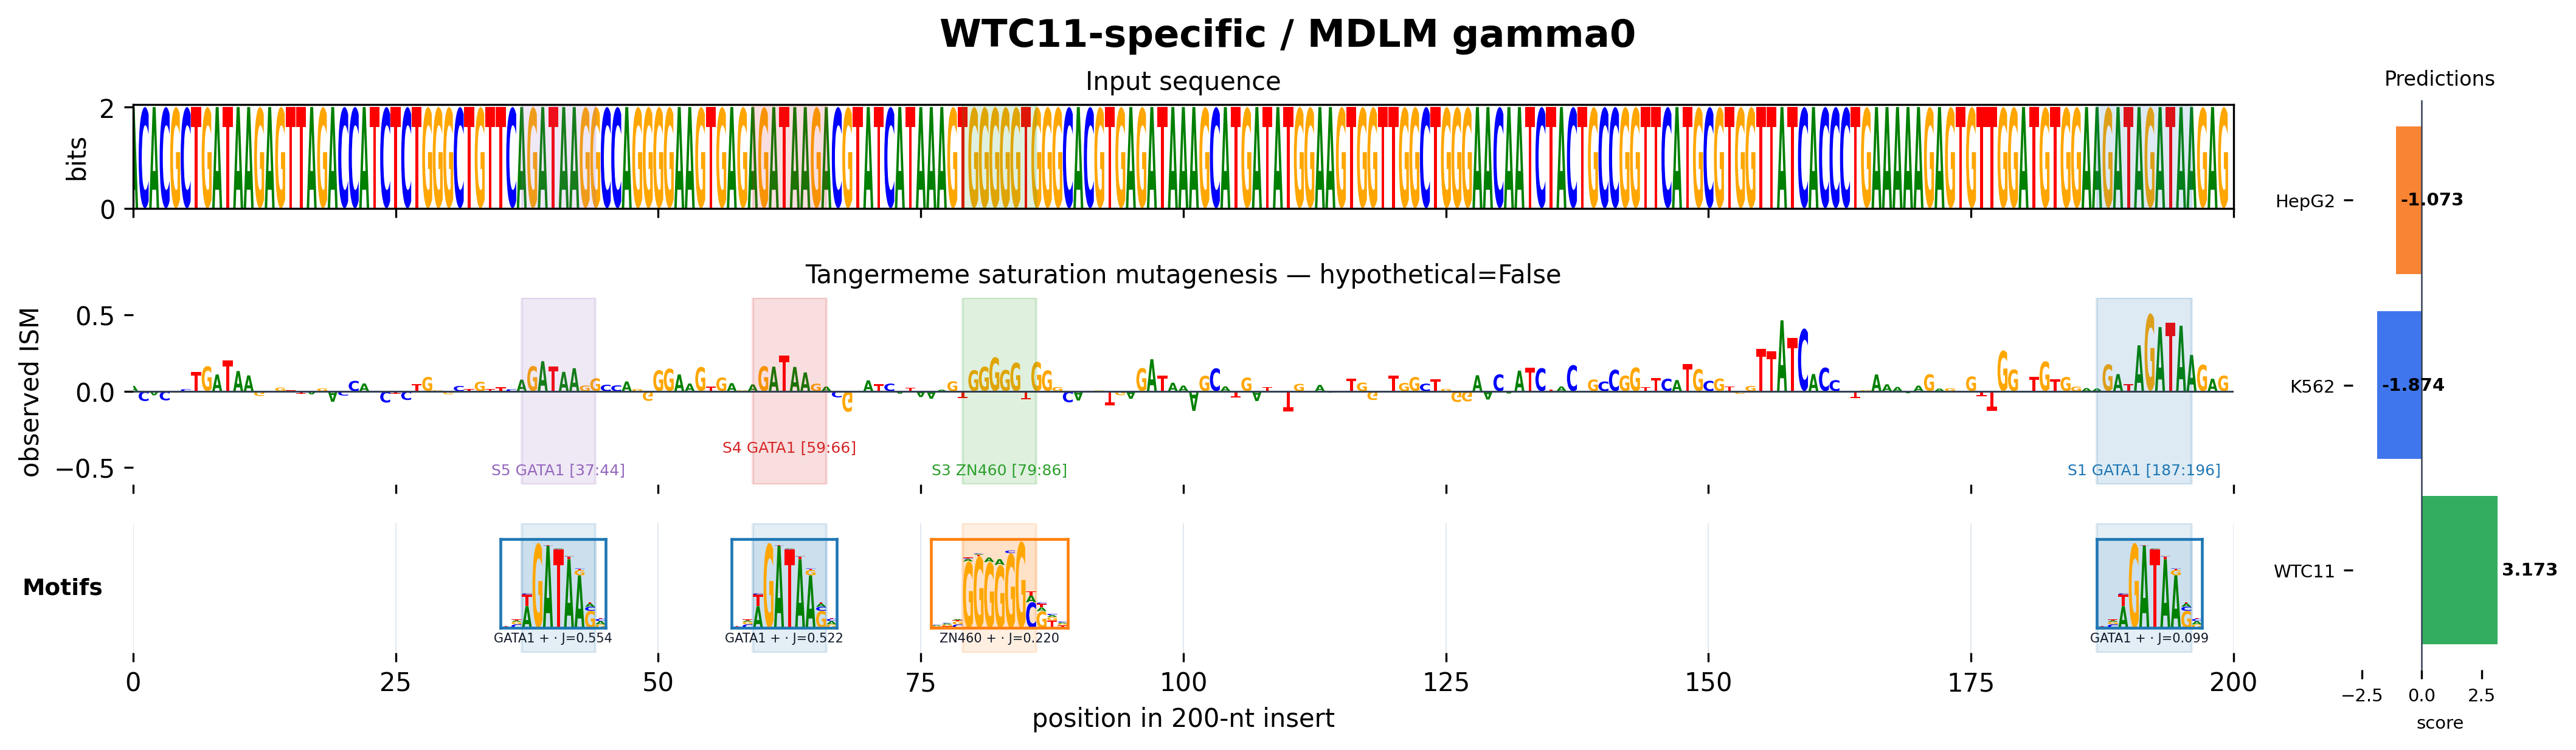

In [31]:
entry = generated_entries['WTC11-specific / MDLM gamma0']
annotation_payload = {
    'example': entry['example'],
    'source_file': entry['source_file'],
    'source_row': entry['source_row'],
    'sequence': entry['sequence'],
    'seqlets': entry['seqlets'],
    'annotation_attrs': {
        'reference_similarity_matrix': entry['reference_similarity_matrix'],
    },
    'display_title': entry['example'],
}
positioned_hits = select_non_overlapping_macroape_hits(
    annotation_payload,
    motif_db,
    threshold=0.05,
)
aligned_path = ALIGNED_FIGURE_DIR / 'generated_03_aligned.png'
render_position_aligned_macroape_logo(
    annotation_payload,
    np.asarray(entry['ism']['observed_attr']),
    motif_db,
    positioned_hits['motif'].drop_duplicates().tolist(),
    entry['predictions'],
    aligned_path,
    threshold=0.05,
    dpi=300,
    positioned_hits=positioned_hits,
    single_motif_track=True,
    figure_width=14.0,
    figure_height=4.0,
    show_summary_panel=False,
    prediction_only_panel=True,
    frameless=True,
    horizontal_labels=True,
    show_title_counts=False,
)
display(Image(filename=str(aligned_path), width=1600))


**Теоретическая интерпретация для WTC11-specific design.**

- **GATA1:** canonical erythroid regulator; высокий motif similarity не означает, что GATA1 активирует WTC11. В contrastive модели такой site может участвовать и в отрицательном сигнале для K562/HepG2.
- **ZNF460:** zinc-finger motif с ограниченной функциональной специфичностью; match следует считать гипотезой о дополнительном sequence pattern.
- Для pluripotent WTC11 важен знак ISM и сравнение cell-line outputs, а не только имя ближайшего motif.


## Как читать результат

- **Input sequence:** буквенный sequence-logo на общей координатной оси 0–200.
- **Observed ISM:** вклад фактически присутствующих оснований; цветные области и подписи отмечают аннотированные seqlets.
- **Motifs:** одна строка непересекающихся потенциальных HOCOMOCO matches непосредственно под соответствующими координатами seqlets.
- **Jaccard:** MacroAPE-сходство seqlet PFM и reference motif; отбираются hits строго выше `0.05`.
- Reference motif размещается внутри matched seqlet interval. MacroAPE не возвращает точный base-level offset или strand, поэтому это позиционное выравнивание по seqlet, а не доказанное нуклеотидное выравнивание.

Motif match означает «модель использует паттерн, похожий на этот motif», а не экспериментальное доказательство связывания данного TF.


# Задания

Все последовательности должны иметь длину 200 nt;
координаты мотивов задаются как 0-based полуинтервалы.
Для корректного сравнения вариантов используйте одну предсказательную модель и явно фиксируйте изменяемые позиции, fitness и критерий интерпретации.


## Задание 1 — спроектировать синтетическую HepG2-активную последовательность

Создать собственную 200-nt последовательность и проверить варианты

**Консенсусы мотивов из HOCOMOCO v14:**

- HNF4A — GGGTTCAAAGTCCAC;
- FOSL2/AP-1 — GGATGAGTCATC;
- GABPA — AACCGGAAGTGG;
- CREB5 — AATGATGTCAT.

В интерактивном редакторе ниже можно вручную менять 200-nt sequence, выбрать консенсус и позицию вставки, затем выбрать fitness function и запустить предсказание и ISM.

Подготовить варианты без мотивов, только A, только B и A+B.
Сравнить HepG2/K562/WTC11 predictions, observed ISM, seqlets и motif annotations.


In [32]:
TASK1_CONSENSUSES = {
    'HNF4A — GGGTTCAAAGTCCAC': 'GGGTTCAAAGTCCAC',
    'FOSL2/AP-1 — GGATGAGTCATC': 'GGATGAGTCATC',
    'GABPA — AACCGGAAGTGG': 'AACCGGAAGTGG',
    'CREB5 — AATGATGTCAT': 'AATGATGTCAT',
}
task1_sequence_widget = widgets.Textarea(
    value=BACKGROUND_SEQUENCE,
    description='200-nt DNA:',
    layout=widgets.Layout(width='100%', height='120px'),
)
task1_motif_widget = widgets.Dropdown(
    options=list(TASK1_CONSENSUSES.items()),
    description='motif:',
)
task1_position_widget = widgets.BoundedIntText(
    value=52,
    min=0,
    max=199,
    description='0-based start:',
)
task1_insert_button = widgets.Button(
    description='Insert consensus',
    button_style='info',
)
task1_status_widget = widgets.HTML()
task1_fitness_widget = widgets.Dropdown(
    options=FITNESS_NAMES,
    value='activity HepG2',
    description='fitness:',
)
task1_run_button = widgets.Button(
    description='Run predictions + ISM',
    button_style='primary',
)
task1_output_widget = widgets.Output()
task1_insert_button.on_click(partial(
    insert_consensus_into_widget,
    sequence_widget=task1_sequence_widget,
    motif_widget=task1_motif_widget,
    position_widget=task1_position_widget,
    status_widget=task1_status_widget,
))
task1_run_button.on_click(partial(
    run_custom_sequence_widget,
    sequence_widget=task1_sequence_widget,
    fitness_widget=task1_fitness_widget,
    output_widget=task1_output_widget,
    clear_output_fn=clear_output,
    run_ism_fn=run_ism,
    predict_sequences_fn=predict_sequences,
    cell_types=CELL_TYPES,
))
display(
    task1_sequence_widget,
    widgets.HBox([
        task1_motif_widget,
        task1_position_widget,
        task1_insert_button,
    ]),
    task1_status_widget,
    widgets.HBox([task1_fitness_widget, task1_run_button]),
    task1_output_widget,
)


Textarea(value='ATTTGACGGAACAAAACTTTGTCAATACTGATGTAATGATTAATTGAAAGTGTATCCGAAAGGGGAGTCAGACGAAACAATGCACTAAGGAAGA…

HTML(value='')

Output()

## Задание 2 — сделать ISM одной последовательности для разных клеточных линий

Выбрать одну последовательность и выполнить ISM отдельно с fitness для HepG2, K562, WTC11 и дополнительно HepG2 минус K562.

Сравнить:

- расположение положительных и отрицательных ISM-пиков;
- набор seqlets;
- motif annotations;
- изменение знака attribution одного участка между клеточными линиями.

**Исследовательский вопрос:** какие участки отвечают за общую активность, а какие — за клеточную специфичность?


## Задание 3 — исследовать влияние расстояния и ориентации motifs

Взять два motifs и разместить их в одной фоновой последовательности с расстояниями 5, 10, 20 и 40 bp.

Дополнительно создать варианты:

- motif B в прямой ориентации;
- motif B в reverse-complement ориентации;
- motifs поменяны местами.

Все остальные позиции должны оставаться одинаковыми.

**Исследовательский вопрос:** зависит ли активность от расстояния, порядка и ориентации motifs, то есть существует ли у модели регуляторная «грамматика»?


## Воспроизводимость и границы интерпретации

- Пересборка пяти natural examples: `scripts/build_teacher_natural_cache.py`.
- Эталонные cache-каталоги имеют `SHA256SUMS`; builders отказываются затирать существующий output и создают результаты только в новом каталоге.
- Prediction и ISM — свойства модели, а не экспериментальное доказательство enhancer activity или TF binding.
- Публичный notebook намеренно содержит только задания 1, 2 и 3 без готовых решений.
